In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from math import pi
import time

from sklearn.metrics import roc_auc_score, accuracy_score
from sklearn.preprocessing import MinMaxScaler
from IPython.display import clear_output

import tensorflow as tf
from keras import layers
import sklearn

In [38]:
# @tf.keras.utils.register_keras_serializable()
# class AnomalyDetector(tf.keras.Model):
#     def __init__(self, **kwargs):
#         super(AnomalyDetector, self).__init__(**kwargs)
#         self.encoder = tf.keras.Sequential([
#             layers.Dense(32, activation=None),
#             layers.BatchNormalization(),
#             layers.LeakyReLU(),
#             layers.Dropout(0.1),
#             layers.Dense(16, activation=None),
#             layers.BatchNormalization(),
#             layers.LeakyReLU(),
#             layers.Dense(8, activation=None),
#             layers.BatchNormalization(),
#             layers.LeakyReLU(),
#         ])

#         self.decoder = tf.keras.Sequential([
#             layers.Dense(16, activation=None),
#             layers.BatchNormalization(),
#             layers.LeakyReLU(),
#             layers.Dropout(0.1),
#             layers.Dense(32, activation=None),
#             layers.BatchNormalization(),
#             layers.LeakyReLU(),
#             layers.Dense(24)
#         ])

#     def call(self, x):
#         encoded = self.encoder(x)
#         decoded = self.decoder(encoded)
#         return decoded

#     def get_config(self):
#         # Return config dictionary; empty because no constructor args
#         base_config = super(AnomalyDetector, self).get_config()
#         return base_config

#     @classmethod
#     def from_config(cls, config):
#         return cls(**config)

@tf.keras.utils.register_keras_serializable()
class AnomalyDetectorNCE(tf.keras.Model):
    def __init__(self, latent_dim=8, **kwargs):
        super().__init__(**kwargs)

        # Encoder
        self.encoder = tf.keras.Sequential([
            layers.Dense(32, activation=None),
            layers.BatchNormalization(),
            layers.LeakyReLU(),
            layers.Dropout(0.1),
            layers.Dense(16, activation=None),
            layers.BatchNormalization(),
            layers.LeakyReLU(),
            layers.Dense(latent_dim, activation=None),
            layers.BatchNormalization(),
            layers.LeakyReLU(),
        ])

        # Decoder
        self.decoder = tf.keras.Sequential([
            layers.Dense(16, activation=None),
            layers.BatchNormalization(),
            layers.LeakyReLU(),
            layers.Dropout(0.1),
            layers.Dense(32, activation=None),
            layers.BatchNormalization(),
            layers.LeakyReLU(),
            layers.Dense(24)  # output dim
        ])

        # NCE Classifier Head
        self.classifier = tf.keras.Sequential([
            layers.Dense(8, activation='relu'),
            layers.Dense(1, activation='sigmoid')  # p(normal)
        ])

    def call(self, x):
        z = self.encoder(x)
        reconstruction = self.decoder(z)
        classification = self.classifier(z)
        return reconstruction, classification

    def get_config(self):
        base_config = super().get_config()
        return base_config

    @classmethod
    def from_config(cls, config):
        return cls(**config)

In [39]:
autoencoder = tf.keras.models.load_model(
    "Models/CAE/8f_cae_nce_model.keras",
    custom_objects={"AnomalyDetectorNCE": AnomalyDetectorNCE}
)

In [40]:
transformed_training_data = pd.read_csv('Dataset/Transformed/Normalised/labelled_transformed_training_data.csv')

# 1. Extract labels (column 6)
training_labels = transformed_training_data.iloc[:, 6].astype(bool)  # Anomalies: True

# 2. Drop label and extra column (column 6 and 7)
training_data = transformed_training_data.drop(
    columns=[transformed_training_data.columns[6], transformed_training_data.columns[7]]
)

# 3. Convert to float32 tensor
training_data = tf.convert_to_tensor(training_data.values, dtype=tf.float32)

# 4. Convert labels to tensor (bool)
training_labels = tf.convert_to_tensor(training_labels.values, dtype=tf.bool)

# 5. Split normal vs anomalous
normal_training_data = tf.boolean_mask(training_data, ~training_labels)
anomalous_training_data = tf.boolean_mask(training_data, training_labels)

In [41]:
transformed_testing_data = pd.read_csv('Dataset/Transformed/Normalised/labelled_transformed_testing_data.csv')

# 1. Extract labels (column 6)
testing_labels = transformed_testing_data.iloc[:, 6].astype(bool)  # Anomalies: True

# 2. Drop label and extra column (column 6 and 7)
testing_data = transformed_testing_data.drop(
    columns=[transformed_testing_data.columns[6], transformed_testing_data.columns[7]]
)

# 3. Convert to float32 tensor
testing_data = tf.convert_to_tensor(testing_data.values, dtype=tf.float32)

# 4. Convert labels to tensor (bool)
testing_labels = tf.convert_to_tensor(testing_labels.values, dtype=tf.bool)

# 5. Split normal vs anomalous
normal_testing_data = tf.boolean_mask(testing_data, ~testing_labels)
anomalous_testing_data = tf.boolean_mask(testing_data, testing_labels)

In [42]:
from sklearn.ensemble import IsolationForest

latent_train = autoencoder.encoder(normal_training_data)

iso_forest = IsolationForest(contamination=0.1, random_state=42)  # contamination = expected anomaly rate
iso_forest.fit(np.array(latent_train)) 


,n_estimators,100
,max_samples,'auto'
,contamination,0.1
,max_features,1.0
,bootstrap,False
,n_jobs,None
,random_state,42
,verbose,0
,warm_start,False


In [43]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score
)
import numpy as np
import tensorflow as tf
from keras import layers
import pandas as pd

def evaluate_model(y_true, y_pred, scores):
    """
    Evaluates a model and returns metrics formatted for copy-pasting.
    
    Parameters:
        y_true (np.array): Ground truth labels (0=normal, 1=anomaly).
        scores (np.array): Anomaly scores (lower = more anomalous).        
    Returns:
        dict: Dictionary of metrics (can print or format for LaTeX).
    """

    precision = precision_score(y_true, y_pred, zero_division=0)
    accuracy = accuracy_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    auroc = roc_auc_score(y_true, scores)

    cm = confusion_matrix(y_true, y_pred)
    clf_report = classification_report(y_true, y_pred, digits=2)

    result = {
        "Precision": f"{precision:.3f}",
        "Accuracy": f"{accuracy:.3f}",
        "Recall": f"{recall:.3f}",
        "F1-Score": f"{f1:.3f}",
        "Matrix": f"TP={cm[1,1]}, FP={cm[0,1]}, FN={cm[1,0]}, TN={cm[0,0]}",
        "AUROC": f"{auroc:.3f}",
        "Clf Report": clf_report.strip()
    }

    return result


In [44]:
# --- Usage with Isolation Forest ---
latent_test = autoencoder.encoder(testing_data)

# Convert TF tensor to numpy if needed
latent_test_np = np.array(latent_test)

preds = iso_forest.predict(latent_test_np)  # -1 = anomaly, 1 = normal
preds = np.where(preds == -1, 1, 0)  # Convert to 0=normal, 1=anomaly

scores = iso_forest.decision_function(latent_test_np)  # higher = more normal
y_true = np.array(testing_labels).astype(int)[:len(scores)]

metrics = evaluate_model(
    y_true=y_true,
    y_pred=preds,
    scores=scores
)

for k, v in metrics.items():
    print(f"{k}: {v}")

Precision: 0.919
Accuracy: 0.894
Recall: 0.968
F1-Score: 0.943
Matrix: TP=165942, FP=14543, FN=5517, TN=2965
AUROC: 0.518
Clf Report: precision    recall  f1-score   support

           0       0.35      0.17      0.23     17508
           1       0.92      0.97      0.94    171459

    accuracy                           0.89    188967
   macro avg       0.63      0.57      0.59    188967
weighted avg       0.87      0.89      0.88    188967



=== Contamination = 0.01 ===
Confusion Matrix:
[[ 13630   3878]
 [164193   7266]]
              precision    recall  f1-score   support

           0      0.077     0.779     0.140     17508
           1      0.652     0.042     0.080    171459

    accuracy                          0.111    188967
   macro avg      0.364     0.410     0.110    188967
weighted avg      0.599     0.111     0.085    188967

AUROC: 0.518

=== Contamination = 0.05 ===
Confusion Matrix:
[[  9012   8496]
 [158065  13394]]
              precision    recall  f1-score   support

           0      0.054     0.515     0.098     17508
           1      0.612     0.078     0.139    171459

    accuracy                          0.119    188967
   macro avg      0.333     0.296     0.118    188967
weighted avg      0.560     0.119     0.135    188967

AUROC: 0.518

=== Contamination = 0.1 ===
Confusion Matrix:
[[  2965  14543]
 [  5517 165942]]
              precision    recall  f1-score   support

           0     

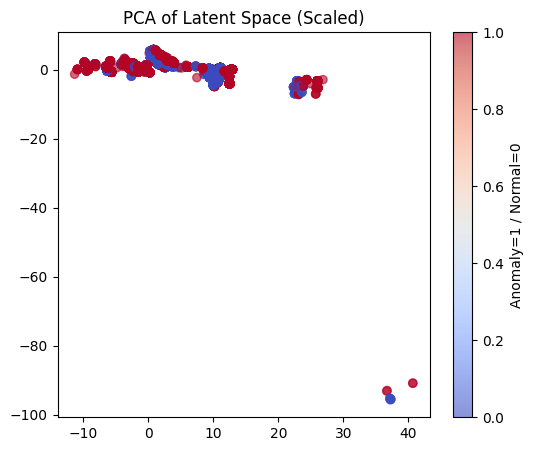

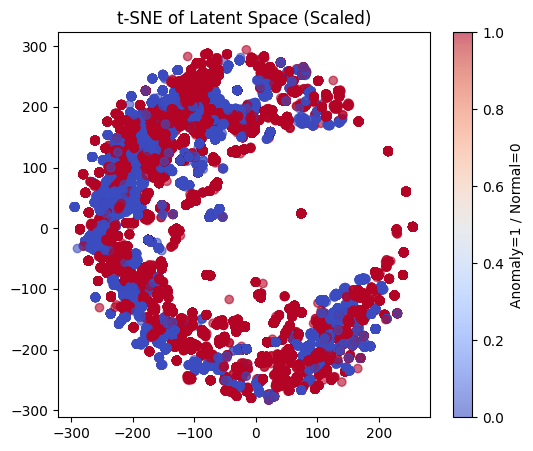

In [45]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# 1️⃣ Convert latent space to numpy
latent_train_np = np.array(autoencoder.encoder(normal_training_data))
latent_test_np = np.array(autoencoder.encoder(testing_data))
y_true = np.array(testing_labels).astype(int)

# 2️⃣ Scaling check
scaler = StandardScaler()
latent_train_scaled = scaler.fit_transform(latent_train_np)
latent_test_scaled = scaler.transform(latent_test_np)

# 3️⃣ Try Isolation Forest with different contamination rates
for cont in [0.01, 0.05, 0.1, 0.2]:
    print(f"\n=== Contamination = {cont} ===")
    iso_forest = IsolationForest(contamination=cont, random_state=42)
    iso_forest.fit(latent_train_scaled)

    preds = iso_forest.predict(latent_test_scaled)
    preds = np.where(preds == -1, 1, 0)  # map -1 to anomaly=1, 1 to normal=0
    scores = iso_forest.decision_function(latent_test_scaled)

    cm = confusion_matrix(y_true, preds)
    print(f"Confusion Matrix:\n{cm}")
    print(classification_report(y_true, preds, digits=3))
    print(f"AUROC: {roc_auc_score(y_true, scores):.3f}")

# 4️⃣ Visualize latent space separability
def plot_latent(latent, labels, title):
    pca = PCA(n_components=2)
    latent_pca = pca.fit_transform(latent)
    plt.figure(figsize=(6,5))
    plt.scatter(latent_pca[:,0], latent_pca[:,1], c=labels, cmap='coolwarm', alpha=0.6)
    plt.colorbar(label="Anomaly=1 / Normal=0")
    plt.title(title)
    plt.show()

plot_latent(latent_test_scaled, y_true, "PCA of Latent Space (Scaled)")

# Optional: t-SNE (slower but better for cluster inspection)
tsne = TSNE(n_components=2, random_state=42, perplexity=30)
latent_tsne = tsne.fit_transform(latent_test_scaled)
plt.figure(figsize=(6,5))
plt.scatter(latent_tsne[:,0], latent_tsne[:,1], c=y_true, cmap='coolwarm', alpha=0.6)
plt.colorbar(label="Anomaly=1 / Normal=0")
plt.title("t-SNE of Latent Space (Scaled)")
plt.show()
